# The Forgotten Bias of SIRENs: A Theoretical Analysis of Sinusoidal Network Initialization — figures and numerical checks

Companion notebook of the paper. It produces every figure and runs automatic checks of the statements.

**Conventions (checked against the [official notebook of Sitzmann et al.](https://colab.research.google.com/github/vsitzmann/siren/blob/master/explore_siren.ipynb#activations)).**
A `SineLayer` computes `sin(omega_0 * linear(x))`, with `first_omega_0 = hidden_omega_0 = 30`. Hence, in effective parameters:
- first layer: weight $\omega_0W$, $W\sim\mathcal U(-1/n_0,1/n_0)$, i.e. $\mathcal U(-1,1)$ for $n_0=1$;
- hidden layers: weights $\mathcal U(-c/\sqrt n,c/\sqrt n)$ with $c=\sqrt6$, $C_W=c^2/3=2$;
- biases are not re-initialized: PyTorch default $\mathcal U(-1/\sqrt{n_\mathrm{in}},1/\sqrt{n_\mathrm{in}})$, multiplied by $\omega_0$.

**Notation.** For a real random variable $Z$: $m_n[Z]=\mathbb E[T_n(\sin Z)]$ (Chebyshev moments of the phase $Z$) and $\gamma_Z=\mathbb E[\cos 2Z]=-m_2[Z]$. The bias enters the deep-layer recursion only through $\gamma_b=\mathbb E[\cos 2b]$.

**The six configurations.**
- **R0** — Theorem 1.8 of Sitzmann et al.: $c=\sqrt6$, no bias.
- **R1** — the actual PyTorch code of Sitzmann et al.: $c=\sqrt6$, effective hidden biases $\mathcal U(-\alpha,\alpha)$ with $\alpha=\omega_0'/\sqrt n$ (regime $\omega_0'=\alpha\sqrt n\to\infty$ for the hidden-bias frequency, with the first-layer frequency $\omega_0$ fixed).
- **R2** — Combette et al., point $\sigma_a=1$: $C_W=2/(1+e^{-2})$, Gaussian biases $\mathcal N(0,1-\tanh 1)$.
- **R3** — Combette et al., point $\sigma_a=0$: $C_W=1$, no bias (degenerate fixed point $s^\star=0$).
- **R4** — this paper: $c=\sqrt6$, biases $\mathcal U(-\pi/2,\pi/2)$ (activations exactly arcsine at every layer and width, Corollary 2.15).
- **R5** — this paper: $c=\sqrt6$, constant biases equal to $\pi/4$.

Style: empirical quantities (Monte Carlo) are discrete markers; theory is drawn with solid lines. Figures are saved in `figs/`.

## Numerical methods used by the helper functions

* **Deep-layer fixed point `s_star`.** No closed form for general $\gamma_b$: fixed-point iteration $s\mapsto\frac{C_W}{2}(1-\gamma_be^{-2s})$, 20 000 steps from $s=1$. Convergence is guaranteed by Proposition A.6 (contraction or monotone convergence); the checks verify a residual below $10^{-12}$.
* **Kolmogorov distance to the arcsine law `dkol_from_moments`.** Kolmogorov identity (Theorem 2.11(iii)): $F_Y(\cos v)-F_A(\cos v)=-\frac2\pi\sum_n\frac{m_n}{n}\sin(nv)$. For a Gaussian phase, $|m_n|\leq e^{-sn^2/2}$, so the series is truncated at $K=80$ terms (neglected tail far below machine precision for the variances used); the supremum is taken over the nodes of a uniform subdivision of $]0,\pi[$ into 20 000 intervals. For uniform biases, the exact coefficients $\phi_b(n)=\mathrm{sinc}(nA)$ are used.
* **Empirical distances `ecdf_dist_arc`, `dkol_empirical`.** Exact supremum between an empirical distribution function and a continuous one, $\max_i\max\{i/N-F(z_{(i)}),\,F(z_{(i)})-(i-1)/N\}$ on the sorted sample.


In [ ]:
import numpy as np, os, time
import matplotlib.pyplot as plt
from scipy.special import sici
from scipy.stats import norm
from scipy.optimize import brentq
from scipy.integrate import quad_vec

os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})
rng = np.random.default_rng(2026)
T0 = time.time()
MK = dict(ls="none", marker="o", ms=3.2, mfc="none", mew=0.8)  # style of empirical markers


def sinc(u):
    return np.sinc(np.asarray(u) / np.pi)


def F_arc(y):
    return 0.5 + np.arcsin(np.clip(y, -1, 1)) / np.pi


def f_arc(y):
    return 1 / (np.pi * np.sqrt(1 - y**2))


SI_PI = sici(np.pi)[0]


def hist_points(data, bins, rng_=None):
    h, e = np.histogram(data, bins=bins, range=rng_, density=True)
    return (e[1:] + e[:-1]) / 2, h


# ---- bias laws (effective units): ('none',) | ('const', beta) | ('gauss', beta, C_b) | ('unif', beta, A)
def bias_sample(law, k):
    if law[0] == "none":
        return np.zeros(k)
    if law[0] == "const":
        return np.full(k, law[1])
    if law[0] == "gauss":
        return law[1] + (rng.normal(0, np.sqrt(law[2]), k) if law[2] > 0 else 0)
    if law[0] == "unif":
        return law[1] + rng.uniform(-law[2], law[2], k)


def bias_gamma(law):  # gamma_b = E[cos 2b] = -m_2[b]
    if law[0] == "none":
        return 1.0
    if law[0] == "const":
        return np.cos(2 * law[1])
    if law[0] == "gauss":
        return np.cos(2 * law[1]) * np.exp(-2 * law[2])
    if law[0] == "unif":
        return np.cos(2 * law[1]) * sinc(2 * law[2])


def bias_var(law):
    if law[0] == "gauss":
        return law[2]
    if law[0] == "unif":
        return law[2] ** 2 / 3
    return 0.0


def bias_mean(law):
    return 0.0 if law[0] == "none" else law[1]


def bias_phi(law, n):  # E[cos n(b - beta)]
    if law[0] in ("none", "const"):
        return 1.0
    if law[0] == "gauss":
        return np.exp(-law[2] * n**2 / 2)
    if law[0] == "unif":
        return sinc(n * law[2])


# ---- theory
def s_theory(x, L, w0, CW, bfirst, bhidden):
    g1, gh = bias_gamma(bfirst), bias_gamma(bhidden)
    s = [w0**2 * x**2 / 3, CW / 2 * (1 - g1 * sinc(2 * w0 * x))]
    while len(s) < L:
        s.append(CW / 2 * (1 - gh * np.exp(-2 * s[-1])))
    return s


def s_star(CW, g, it=20000):
    s = 1.0
    for _ in range(it):
        s = CW / 2 * (1 - g * np.exp(-2 * s))
    return s


def chi_star(CW, g):
    return CW - s_star(CW, g)


def gamma_star(CW):
    return (2 / CW - 1) * np.exp(2 * (CW - 1))


def bias_eps_moments(law):  # E[(b-beta)^2], E[(b-beta)^4]
    if law[0] == "gauss":
        return law[2], 3 * law[2] ** 2
    if law[0] == "unif":
        return law[2] ** 2 / 3, law[2] ** 4 / 5
    return 0.0, 0.0


def measure_deep(CW, bf, bh, n, L=12, M=300, lmin=6, nnet=1):
    # variance averaged over layers lmin..L, gradient ratios g_{l-1}/g_l averaged over l = lmin..L-1,
    # each averaged over nnet independent networks
    xg = np.linspace(-1, 1, M)
    Vs, Cs = [], []
    for _ in range(nnet):
        Zs, Ws = simulate(xg, n, L, W0, CW, bf, bh, keep_W=True)
        Vs.append(np.mean([np.mean((Z - bias_mean(bh)) ** 2) for Z in Zs[lmin - 1 :]]))
        v = rng.normal(0, 1, n)
        dX = np.tile(v, (M, 1))
        g = {}
        for l in range(L, 0, -1):
            dZ = np.cos(Zs[l - 1]) * dX
            g[l] = np.mean(dX**2)
            if l > 1:
                dX = dZ @ Ws[l - 1]
        Cs.append(np.mean([g[l - 1] / g[l] for l in range(lmin, L)]))
    return np.mean(Vs), np.mean(Cs)


# statement numbers of the paper, used in the legends
NUM = {
    "lois": "2.5",
    "crit": "2.7",
    "R5": "2.4",
    "cheb": "2.11",
    "unif": "2.13",
    "gauss": "2.14",
    "arcb": "2.15",
    "mix": "A.3",
    "depth": "A.4",
    "obst": "A.8",
}


def ref(t):
    for k, v in NUM.items():
        t = t.replace("§" + k + "§", v)
    return t


# ---- Chebyshev moments and Kolmogorov distance
V_GRID = (
    np.arange(1, 20000) * np.pi / 20000
)  # interior nodes of a uniform subdivision of (0, pi) into 20 000 intervals


def dkol_from_moments(m, v=V_GRID):
    s = np.zeros_like(v)
    for n, mn in enumerate(m, start=1):
        if mn != 0:
            s += mn * np.sin(n * v) / n
    return 2 / np.pi * np.max(np.abs(s))


def moments_phase(s, beta, phib=lambda n: 1.0, K=80):
    return np.array(
        [np.cos(k * (beta - np.pi / 2)) * np.exp(-s * k * k / 2) * phib(k) for k in range(1, K + 1)]
    )


def dkol_gauss(s, beta):
    return dkol_from_moments(moments_phase(s, beta))


def ecdf_dist_arc(y):
    y = np.sort(np.ravel(y))
    n = len(y)
    F = F_arc(y)
    i = np.arange(1, n + 1)
    return max(np.max(i / n - F), np.max(F - (i - 1) / n))


# ---- simulation (effective parametrization)
def simulate(x, n, L, w0, CW, bfirst, bhidden, keep_W=False):
    c = np.sqrt(3 * CW)
    M = len(x)
    W1 = rng.uniform(-1, 1, n)
    Zs = [w0 * np.outer(x, W1) + bias_sample(bfirst, n)]
    Ws = [W1]
    for l in range(2, L + 1):
        W = rng.uniform(-1, 1, (n, n)) * c / np.sqrt(n)
        Zs.append(np.sin(Zs[-1]) @ W.T + bias_sample(bhidden, n))
        Ws.append(W)
    return (Zs, Ws) if keep_W else Zs


def grad_ratios(Zs, Ws, M, n):
    v = rng.normal(0, 1, n)
    dX = np.tile(v, (M, 1))
    g = {}
    L = len(Zs)
    for l in range(L, 0, -1):
        dZ = np.cos(Zs[l - 1]) * dX
        g[l] = np.mean(dX**2)
        if l > 1:
            dX = dZ @ Ws[l - 1]
    return [g[l - 1] / g[l] for l in range(L, 2, -1)]


W0 = 30.0
CW_R2, CB_R2 = 2 / (1 + np.exp(-2)), 1 - np.tanh(1)


def R1_biases(n, w0=W0, n0=1):
    return ("unif", 0.0, w0 / np.sqrt(n0)), ("unif", 0.0, w0 / np.sqrt(n))


CONF = {  # name: (C_W, first-layer bias, hidden bias)   [R1 is given for a width n]
    "R0": lambda n=None: (2.0, ("none",), ("none",)),
    "R1": lambda n=2048: (2.0,) + R1_biases(n),
    "R2": lambda n=None: (CW_R2, ("gauss", 0.0, CB_R2), ("gauss", 0.0, CB_R2)),
    "R5": lambda n=None: (2.0, ("const", np.pi / 4), ("const", np.pi / 4)),
    "R4": lambda n=None: (2.0, ("unif", 0.0, np.pi / 2), ("unif", 0.0, np.pi / 2)),
    "R3": lambda n=None: (1.0, ("none",), ("none",)),
}
CONFIGS = ["R0", "R1", "R2", "R3", "R4", "R5"]
LABEL = {
    "R0": "R0 (Thm 1.8)",
    "R1": "R1 (PyTorch code)",
    "R2": r"R2 (Combette et al., $\sigma_a=1$)",
    "R5": r"R5 ($\beta=\pi/4$)",
    "R4": r"R4 ($\mathcal{U}(-\pi/2,\pi/2)$)",
    "R3": r"R3 (Combette et al., $\sigma_a=0$)",
}
COL = {"R0": "C0", "R1": "C1", "R2": "C2", "R5": "C3", "R4": "C4", "R3": "C5"}
print("Si(pi) =", SI_PI)

Si(pi) = 1.8519370519824658


## Figure — first layer (not Gaussian)

Without conditioning on the input, $\omega_0WX^{(0)}$ has density $\frac{1}{2\omega_0}\log\frac{\omega_0}{|z|}$, and characteristic function $\mathrm{Si}(\omega_0t)/(\omega_0t)$.

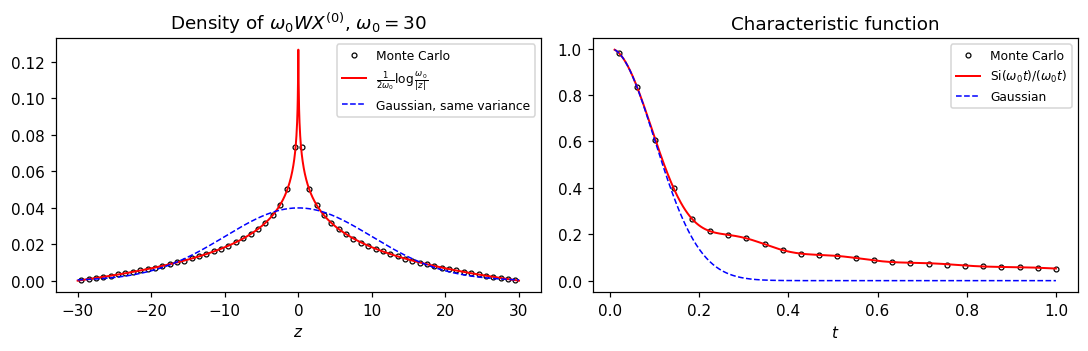

first layer: density and characteristic function compared with closed forms


In [ ]:
z = W0 * rng.uniform(-1, 1, 2_000_000) * rng.uniform(-1, 1, 2_000_000)
zz = np.linspace(-W0, W0, 2000)
zz = zz[np.abs(zz) > 1e-3]
sd = W0 / 3
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
c_, h_ = hist_points(z, 60, (-W0, W0))
ax[0].plot(c_, h_, color="k", label="Monte Carlo", **MK)
ax[0].plot(
    zz,
    np.log(W0 / np.abs(zz)) / (2 * W0),
    "r",
    lw=1.3,
    label=r"$\frac{1}{2\omega_0}\log\frac{\omega_0}{|z|}$",
)
ax[0].plot(zz, norm.pdf(zz, 0, sd), "b--", lw=1, label="Gaussian, same variance")
ax[0].set_xlabel("$z$")
ax[0].set_title(r"Density of $\omega_0 W X^{(0)}$, $\omega_0=30$")
ax[0].legend(fontsize=8)
t = np.linspace(0.01, 1.0, 400)
te = np.linspace(0.02, 1.0, 25)
ax[1].plot(
    te, [np.mean(np.cos(tt * z[:400000])) for tt in te], color="k", label="Monte Carlo", **MK
)
ax[1].plot(
    t, sici(W0 * t)[0] / (W0 * t), "r", lw=1.3, label=r"$\mathrm{Si}(\omega_0 t)/(\omega_0 t)$"
)
ax[1].plot(t, np.exp(-(sd**2) * t**2 / 2), "b--", lw=1, label="Gaussian")
ax[1].set_xlabel("$t$")
ax[1].set_title("Characteristic function")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figs/fig_first_layer.pdf")
plt.show()
print("first layer: density and characteristic function compared with closed forms")

## Figure — exact variance of the second layer versus the Gaussian heuristic

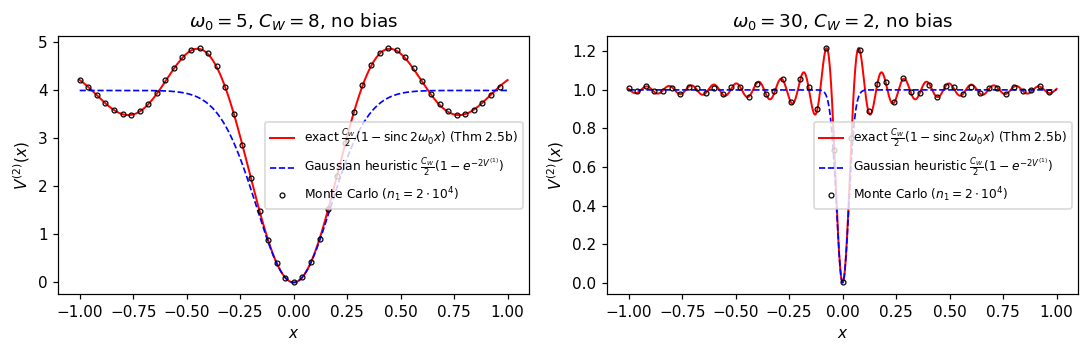

x=0.2, w0=5, C_W=8: exact 2.1814, Gaussian heuristic 1.9463


In [ ]:
x = np.linspace(-1, 1, 800)
xe = x[::16]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for k, (w0, CW) in enumerate([(5.0, 8.0), (30.0, 2.0)]):
    W1 = rng.uniform(-1, 1, 20000)
    Sig = CW * np.mean(np.sin(w0 * np.outer(xe, W1)) ** 2, axis=1)
    s1, s2 = s_theory(x, 2, w0, CW, ("none",), ("none",))
    ax[k].plot(
        x,
        s2,
        "r",
        lw=1.3,
        label=ref(r"exact $\frac{C_W}{2}(1-\mathrm{sinc}\,2\omega_0x)$ (Thm §lois§b)"),
    )
    ax[k].plot(
        x,
        CW / 2 * (1 - np.exp(-2 * s1)),
        "b--",
        lw=1.1,
        label=r"Gaussian heuristic $\frac{C_W}{2}(1-e^{-2V^{(1)}})$",
    )
    ax[k].plot(xe, Sig, color="k", label=r"Monte Carlo ($n_1=2\cdot10^4$)", **MK)
    ax[k].set_xlabel("$x$")
    ax[k].set_ylabel(r"$V^{(2)}(x)$")
    ax[k].set_title(f"$\\omega_0={w0:g}$, $C_W={CW:g}$, no bias")
    ax[k].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figs/fig_variance_layer2.pdf")
plt.show()
V2_EX = 4 * (1 - sinc(2.0))
V2_HE = 4 * (1 - np.exp(-2 * 25 * 0.04 / 3))
print(f"x=0.2, w0=5, C_W=8: exact {V2_EX:.4f}, Gaussian heuristic {V2_HE:.4f}")

## Figure — variance recursion for the six configurations

Variances $V^{(l)}(x)$, $l=2,\dots,6$: infinite-width theory (lines) and one network of width 1024 (markers, sparse).

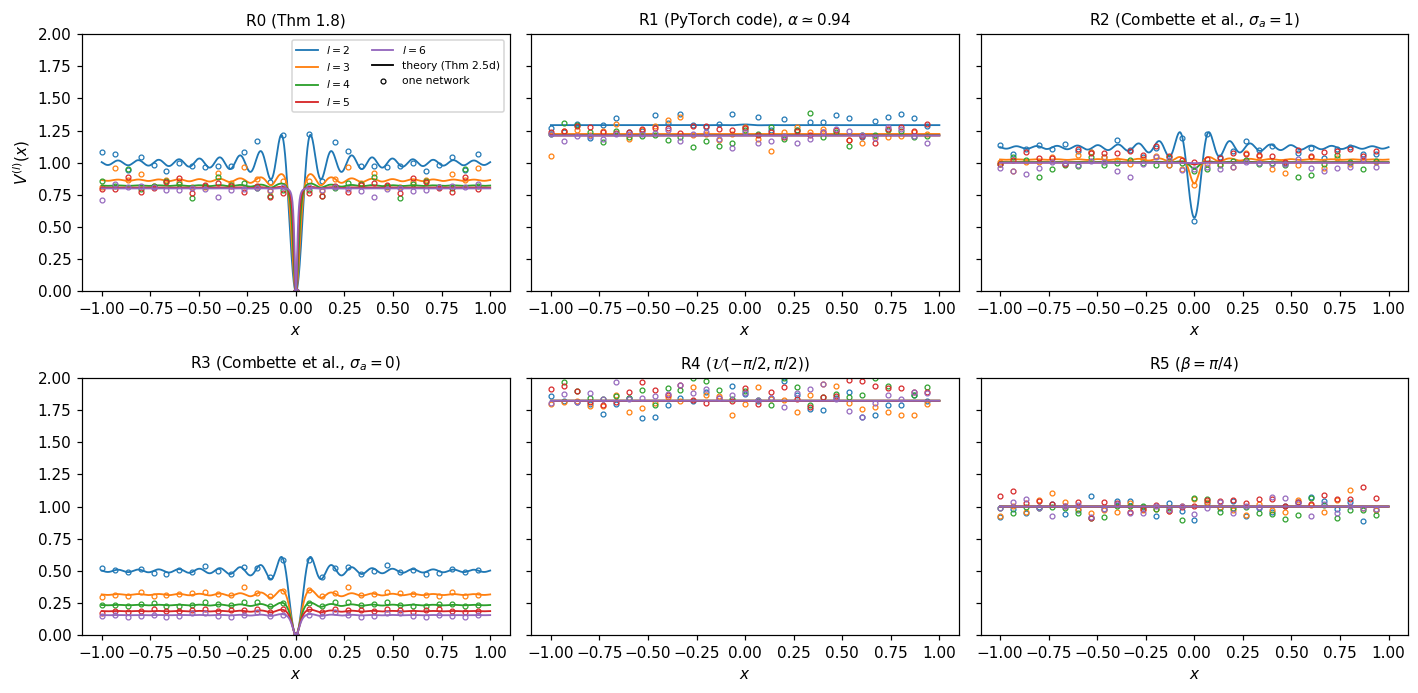

In [ ]:
x = np.linspace(-1, 1, 1200)
L = 6
n = 1024
xs_idx = slice(0, None, 40)
fig, axs = plt.subplots(2, 3, figsize=(13, 6.4), sharey=True)
ax = axs.ravel()
for k, name in enumerate(CONFIGS):
    CW, bf, bh = CONF[name](1024)
    Zs = simulate(x, n, L, W0, CW, bf, bh)
    s = s_theory(x, L, W0, CW, bf, bh)
    for l in range(2, L + 1):
        (line,) = ax[k].plot(x, s[l - 1] + bias_var(bh), lw=1.2, label=f"$l={l}$")
        emp = np.mean((Zs[l - 1] - bias_mean(bh)) ** 2, axis=1)
        ax[k].plot(x[xs_idx], emp[xs_idx], color=line.get_color(), **MK)
    ax[k].set_xlabel("$x$")
    ax[k].set_title(LABEL[name] + (r", $\alpha\simeq0.94$" if name == "R1" else ""), fontsize=10)
    ax[k].set_ylim(0, 2.0)
ax[0].plot([], [], "k", lw=1.2, label=ref("theory (Thm §lois§d)"))
ax[0].plot([], [], color="k", label="one network", **MK)
ax[0].set_ylabel(r"$V^{(l)}(x)$")
ax[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("figs/fig_variance_recursion.pdf")
plt.show()

## Figure — random input: variance and Gaussianity along depth

One network (width 1024), inputs $X\sim\mathcal U(-1,1)$ (2048 draws), histograms pooled over inputs and neurons.
Theory: the infinite-width law of $Z^{(l)}(X)$ is the mixture $\Pi_l$ over $x$ of $G_x+b$, $G_x\sim\mathcal N(0,s^{(l)}(x))$; its variance is $\mathbb E[s^{(l)}(X)]+\mathrm{Var}(b)$. Panel (b): Kolmogorov distance between $\Pi_l$ (no bias) and the Gaussian limit $\mathcal N(0,s^\star)$, computed from the mixture CDF. Panel (b) uses layers 2 to 8 and pools the samples of 48 independent networks (1024 inputs each); simulated values are shown only above twice the finite-size noise level, estimated per layer as the median over 3 pools of 48 R5 networks (whose limit law is exactly Gaussian).

**Numerical method.** The mixture $\Pi_l$ is evaluated through its distribution function $F(t)=\frac12\int_{-1}^1\Phi\big(t/\sqrt{s^{(l)}(x)}\big)dx$, with $s^{(l)}(x)$ computed exactly by the recursion on a grid of 4000 points $x\in[-1,1]$ (mean over the grid) and the supremum over 2000 points $t\in[-5,5]$. The pooled noise decreases like $1/\sqrt{\text{number of networks}}$: it is a network-to-network fluctuation, which grows with the depth-to-width ratio.
Along depth, $s^{(l)}(x)\to s^\star$ for almost every $x$, so the mixture becomes Gaussian plus bias (Prop. A.4).

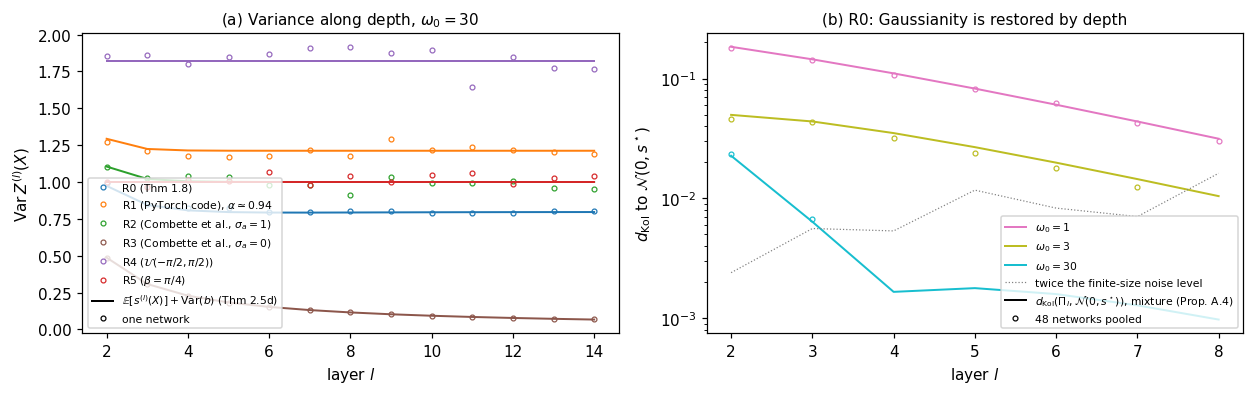

finite-size noise level per layer (R5, exact Gaussian limit): [0.0012 0.0028 0.0027 0.0059 0.0041 0.0035 0.0081]
R0: Var measured [0.994 0.852 0.822 0.826 0.794 0.799 0.805 0.802 0.788 0.788 0.792 0.804
 0.804], theory [0.974 0.845 0.808 0.796 0.793 0.792 0.793 0.794 0.795 0.795 0.796 0.796
 0.796]
R1: Var measured [1.272 1.211 1.173 1.169 1.176 1.215 1.176 1.291 1.217 1.235 1.217 1.202
 1.193], theory [1.293 1.224 1.214 1.212 1.212 1.212 1.212 1.212 1.212 1.212 1.212 1.212
 1.212]
R2: Var measured [1.102 1.027 1.04  1.037 0.978 0.98  0.915 1.031 0.996 0.99  1.01  0.956
 0.951], theory [1.105 1.021 1.005 1.001 1.    1.    1.    1.    1.    1.    1.    1.
 1.   ]
R3: Var measured [0.486 0.307 0.229 0.182 0.152 0.13  0.116 0.104 0.093 0.085 0.077 0.072
 0.068], theory [0.487 0.308 0.229 0.183 0.153 0.131 0.115 0.103 0.093 0.085 0.078 0.072
 0.067]
R4: Var measured [1.855 1.858 1.798 1.85  1.865 1.91  1.917 1.878 1.898 1.643 1.845 1.77
 1.766], theory [1.822 1.822 1.822 1.822 1.822 1.822 

In [ ]:
def mixture_theory_depth(L, w0, CW, bf, bh, grid=np.linspace(-1, 1, 4000)):
    s = s_theory(grid, L, w0, CW, bf, bh)
    e2, _ = bias_eps_moments(bh)
    return np.array([np.mean(s[l - 1]) + e2 for l in range(2, L + 1)])


def dkol_empirical(Z, mean, sigma2):
    z = np.sort(np.ravel(Z))
    n_ = len(z)
    F = norm.cdf((z - mean) / np.sqrt(sigma2))
    i_ = np.arange(1, n_ + 1)
    return max(np.max(i_ / n_ - F), np.max(F - (i_ - 1) / n_))


L = 14
layers = np.arange(2, L + 1)
xs = rng.uniform(-1, 1, 2048)
n = 1024
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.7))
DEPTH = {}
for name in CONFIGS:
    CW, bf, bh = CONF[name](1024)
    Zs = simulate(xs, n, L, W0, CW, bf, bh)
    m = bias_mean(bh)
    Ve = [np.mean((Z - m) ** 2) for Z in Zs[1:]]
    Vt = mixture_theory_depth(L, W0, CW, bf, bh)
    DEPTH[name] = (Ve, Vt)
    ax[0].plot(layers, Vt, color=COL[name], lw=1.3)
    ax[0].plot(
        layers,
        Ve,
        color=COL[name],
        label=LABEL[name] + (r", $\alpha\simeq0.94$" if name == "R1" else ""),
        **MK,
    )
ax[0].plot(
    [], [], "k", lw=1.3, label=ref(r"$\mathbb{E}[s^{(l)}(X)]+\mathrm{Var}(b)$ (Thm §lois§d)")
)
ax[0].plot([], [], color="k", label="one network", **MK)
ax[0].set_xlabel("layer $l$")
ax[0].set_ylabel(r"$\mathrm{Var}\,Z^{(l)}(X)$")
ax[0].legend(fontsize=7)
ax[0].set_title(r"(a) Variance along depth, $\omega_0=30$", fontsize=10)
# panel (b): layers 2 to 8, samples pooled over NPOOL independent networks
LB = 8
layers_b = np.arange(2, LB + 1)
NPOOL = 48
xs_b = xs[:1024]


def pooled_dkol(w0, CW, bf, bh, mean, sigma2, sub=8):
    pools = [[] for _ in range(LB - 1)]
    for _ in range(NPOOL):
        Zs = simulate(xs_b, n, LB, w0, CW, bf, bh)
        for k, Z in enumerate(Zs[1:]):
            pools[k].append(Z[:, ::sub].ravel())
    return np.array([dkol_empirical(np.concatenate(p), mean, sigma2) for p in pools])


# finite-size noise level per layer: R5 has an exactly Gaussian limit N(pi/4, 1),
# so the d_Kol of a pool of R5 networks to N(pi/4, 1) is pure finite-size fluctuation
CW3, bf3, bh3 = CONF["R5"]()
NOISE_L = np.median([pooled_dkol(W0, CW3, bf3, bh3, np.pi / 4, 1.0) for _ in range(3)], axis=0)
s0 = s_star(2.0, 1.0)
tg = np.linspace(-5, 5, 2000)
grid = np.linspace(-1, 1, 4000)


def dkol_mixture_theory(w0, L):
    s = s_theory(grid, L, w0, 2.0, ("none",), ("none",))
    out = []
    for l in range(2, L + 1):
        sd = np.sqrt(np.maximum(s[l - 1], 1e-14))
        F = np.mean(norm.cdf(tg[:, None] / sd[None, :]), axis=1)
        out.append(np.max(np.abs(F - norm.cdf(tg / np.sqrt(s0)))))
    return np.array(out)


for w0, col in [(1.0, "C6"), (3.0, "C8"), (30.0, "C9")]:
    De = pooled_dkol(w0, 2.0, ("none",), ("none",), 0.0, s0)
    Dt = dkol_mixture_theory(w0, LB)
    keep = De > 2 * NOISE_L
    ax[1].semilogy(layers_b, Dt, color=col, lw=1.3, label=f"$\\omega_0={w0:g}$")
    ax[1].semilogy(layers_b[keep], De[keep], color=col, **MK)
    DEPTH[("R0", w0)] = (De, Dt, keep)
ax[1].semilogy(
    layers_b, 2 * NOISE_L, color="gray", lw=0.8, ls=":", label="twice the finite-size noise level"
)
ax[1].semilogy(
    [],
    [],
    "k",
    lw=1.3,
    label=ref(r"$d_{\mathrm{Kol}}(\Pi_l,\mathcal{N}(0,s^\star))$, mixture (Prop. §depth§)"),
)
ax[1].semilogy([], [], color="k", label=f"{NPOOL} networks pooled", **MK)
ax[1].set_xlabel("layer $l$")
ax[1].set_ylabel(r"$d_{\mathrm{Kol}}$ to $\mathcal{N}(0,s^\star)$")
ax[1].legend(fontsize=7)
ax[1].set_title("(b) R0: Gaussianity is restored by depth", fontsize=10)
plt.tight_layout()
plt.savefig("figs/fig_depth_random_input.pdf")
plt.show()
print("finite-size noise level per layer (R5, exact Gaussian limit):", np.round(NOISE_L, 4))
for k_, v in DEPTH.items():
    if isinstance(k_, str):
        print(f"{k_}: Var measured {np.round(v[0],3)}, theory {np.round(v[1],3)}")
    else:
        print(
            f"{k_}: d_Kol measured {np.round(v[0],4)}, theory {np.round(v[1],4)}, shown {v[2].astype(int)}"
        )

## Figure — unconditional second layer (random input)

For $X^{(0)}\sim\mathcal U(-1,1)$ and no bias, the limit law of $Z^{(2)}$ is the Gaussian mixture $\Pi_{\omega_0}=\frac12\int_{-1}^1\mathcal N(0,V^{(2)}(x))\,dx$.
**Numerical method.** Its density is computed by adaptive quadrature in $x$ (`scipy.integrate.quad_vec`, relative tolerance $10^{-9}$); the total variation is then integrated by the trapezoidal rule on 4 000 points of $[-8,8]$ (an even number of points avoids $z=0$, where the density has an integrable logarithmic singularity). Its variance is in closed form with $\mathrm{Si}$.
Panel (d) compares the total-variation distance to $\mathcal N(0,A)$ (numerical, from the exact mixture density; empirical, from binned samples) with the bound $\epsilon(1+\log 1/\epsilon)$.

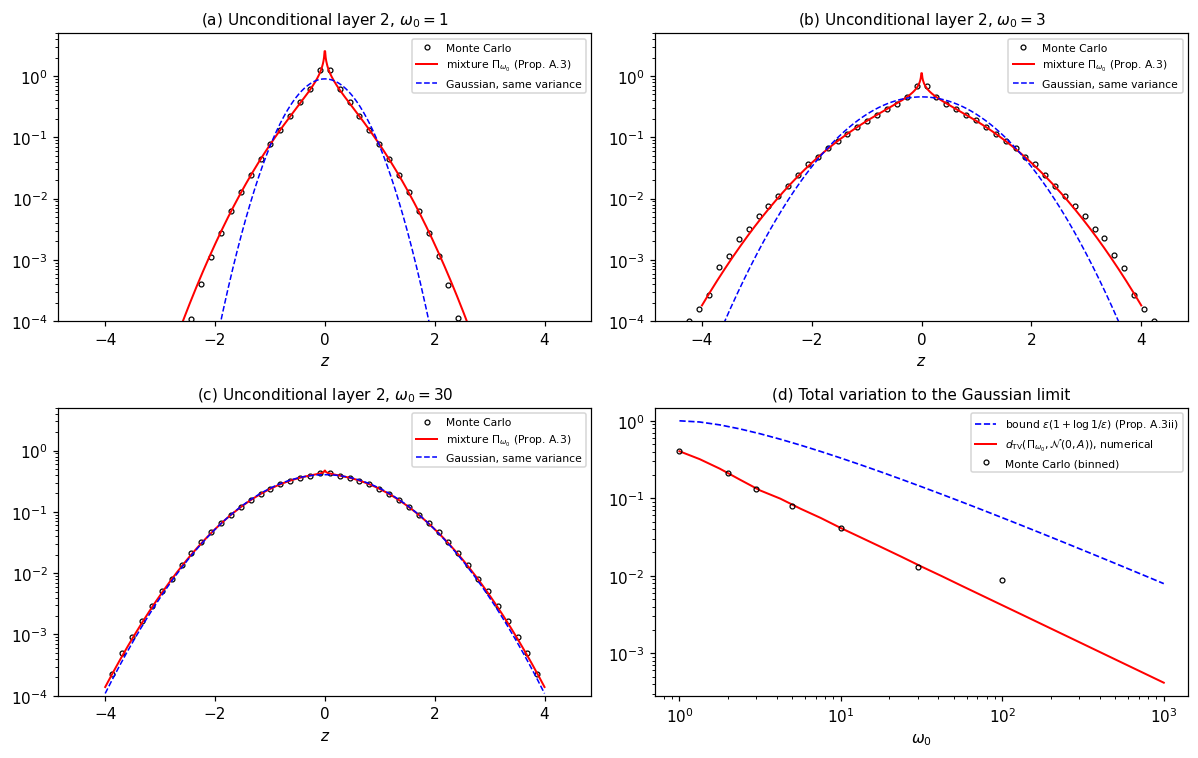

w0=1: variance theory 0.1973, empirical 0.1967
w0=3: variance theory 0.7626, empirical 0.7841
w0=30: variance theory 0.9736, empirical 0.9802
w0=1: d_TV numerical 0.4044, binned Monte Carlo 0.4034, bound 1.0000
w0=2: d_TV numerical 0.2117, binned Monte Carlo 0.2102, bound 0.8466


w0=3: d_TV numerical 0.1332, binned Monte Carlo 0.1320, bound 0.6995
w0=5: d_TV numerical 0.0840, binned Monte Carlo 0.0790, bound 0.5219


w0=10: d_TV numerical 0.0413, binned Monte Carlo 0.0416, bound 0.3303
w0=30: d_TV numerical 0.0139, binned Monte Carlo 0.0130, bound 0.1467


w0=100: d_TV numerical 0.0042, binned Monte Carlo 0.0088, bound 0.0561


In [ ]:
CW_MIX = 2.0
A_ = CW_MIX / 2
B_ = CW_MIX / 2


def V2(x, w0):
    return CW_MIX / 2 * (1 - sinc(2 * w0 * x))


def mixture_density(zg, w0):
    f = lambda xx: norm.pdf(zg, 0, np.sqrt(np.maximum(V2(xx, w0), 1e-300)))
    return quad_vec(f, 0.0, 1.0, epsrel=1e-9, limit=2000)[0]


def mixture_variance(w0):
    return A_ - B_ * sici(2 * w0)[0] / (2 * w0)


def sim_unconditional(w0, nnet, nx=3000, n1=2000, n2=100):
    out = []
    for _ in range(nnet):
        xs_ = rng.uniform(-1, 1, nx)
        W1 = rng.uniform(-1, 1, n1)
        X1 = np.sin(w0 * np.outer(xs_, W1))
        W2 = rng.uniform(-1, 1, (n2, n1)) * np.sqrt(3 * CW_MIX) / np.sqrt(n1)
        out.append((X1 @ W2.T).ravel())
    return np.concatenate(out)


zg = np.linspace(-8, 8, 4000)  # even number of points: z = 0 (log singularity) is avoided


def tv_numeric(w0):
    return 0.5 * np.trapezoid(np.abs(mixture_density(zg, w0) - norm.pdf(zg, 0, np.sqrt(A_))), zg)


def tv_binned(sample, bins=300, lim=6.0):
    e = np.linspace(-lim, lim, bins + 1)
    h, _ = np.histogram(sample, bins=e)
    p_hat = h / len(sample)
    p = np.diff(norm.cdf(e, 0, np.sqrt(A_)))
    return 0.5 * (np.sum(np.abs(p_hat - p)) + abs(1 - p_hat.sum() - (1 - p.sum())))


fig, ax = plt.subplots(2, 2, figsize=(11, 7))
zz = np.linspace(-4, 4, 800)
MIXS = {}
SAMPLES = {}
for k, w0 in enumerate([1.0, 3.0, 30.0]):
    Z2 = sim_unconditional(w0, 120)
    SAMPLES[w0] = Z2
    EV = mixture_variance(w0)
    a = ax.flat[k]
    c_, h_ = hist_points(Z2, 50, (-4.5, 4.5))
    a.plot(c_, h_, color="k", label="Monte Carlo", **MK)
    a.plot(
        zz,
        mixture_density(zz, w0),
        "r",
        lw=1.3,
        label=ref(r"mixture $\Pi_{\omega_0}$ (Prop. §mix§)"),
    )
    a.plot(zz, norm.pdf(zz, 0, np.sqrt(EV)), "b--", lw=1, label="Gaussian, same variance")
    a.set_yscale("log")
    a.set_ylim(1e-4, 5)
    a.set_xlabel("$z$")
    a.legend(fontsize=7)
    a.set_title(f'({"abc"[k]}) Unconditional layer 2, $\\omega_0={w0:g}$', fontsize=10)
    MIXS[w0] = (EV, np.var(Z2))
for w in [2.0, 5.0, 10.0, 100.0]:
    SAMPLES[w] = sim_unconditional(w, 15)
W0T = np.logspace(0.0, 3, 25)
eps = B_ / (A_ * W0T)
ax[1, 1].loglog(
    W0T,
    eps * (1 + np.log(1 / eps)),
    "b--",
    lw=1.1,
    label=ref(r"bound $\epsilon(1+\log 1/\epsilon)$ (Prop. §mix§ii)"),
)
TVN = [tv_numeric(w) for w in W0T]
ax[1, 1].loglog(
    W0T, TVN, "r", lw=1.3, label=r"$d_{\mathrm{TV}}(\Pi_{\omega_0},\mathcal{N}(0,A))$, numerical"
)
TVE = {w: tv_binned(SAMPLES[w]) for w in sorted(SAMPLES)}
ax[1, 1].loglog(list(TVE), list(TVE.values()), color="k", label="Monte Carlo (binned)", **MK)
ax[1, 1].set_xlabel(r"$\omega_0$")
ax[1, 1].legend(fontsize=7)
ax[1, 1].set_title("(d) Total variation to the Gaussian limit", fontsize=10)
plt.tight_layout()
plt.savefig("figs/fig_mixture_layer2.pdf")
plt.show()
for w0, v in MIXS.items():
    print("w0={:g}: variance theory {:.4f}, empirical {:.4f}".format(w0, *v))
for w in TVE:
    print(
        f"w0={w:g}: d_TV numerical {tv_numeric(w):.4f}, binned Monte Carlo {TVE[w]:.4f}, bound {B_/(A_*w)*(1+np.log(A_*w/B_)):.4f}"
    )

## Figure — the $(C_W,\gamma_b)$ plane

Deep-layer fixed point: $s^\star=\frac{C_W}{2}(1-\gamma_b e^{-2s^\star})$, $\chi=C_W-s^\star$, critical curve $\gamma_*(C_W)=(2/C_W-1)e^{2(C_W-1)}$.
Chaotic above the curve ($\gamma_b>\gamma_*$), ordered below.

**Numerical method.** $C_W^{\max}$ is the root of $(C-2)e^{2(C-1)}=C$ on $[2.01,3]$ (Brent's method). On the $(C_W,\gamma_b)$ grid, the fixed point is obtained by 4 000 vectorised fixed-point iterations; points where the residual exceeds $10^{-12}$ are reported by the checks.

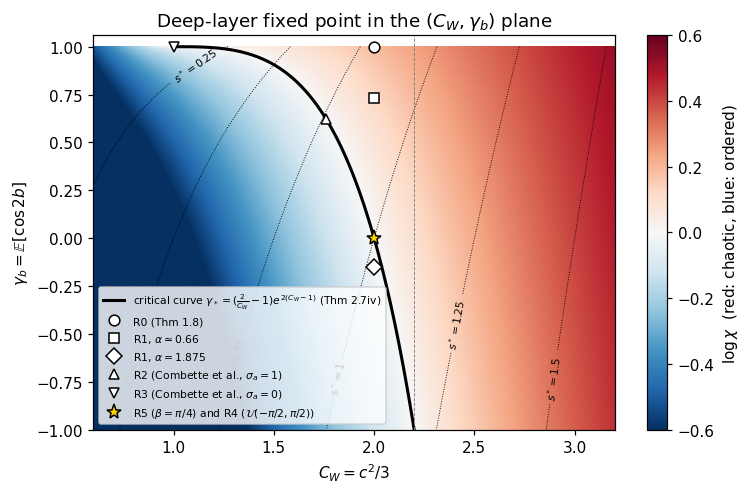

C_W max on the critical curve = 2.1997 (c_max = 2.5689)


In [ ]:
CWs = np.linspace(0.6, 3.2, 260)
gs = np.linspace(-1, 1, 200)
CWg, Gg = np.meshgrid(CWs, gs)
SS = np.ones_like(CWg)
for _ in range(4000):
    SS = CWg / 2 * (1 - Gg * np.exp(-2 * SS))
CHI = CWg / 2 * (1 + Gg * np.exp(-2 * SS))
CWMAX = brentq(lambda C: (C - 2) * np.exp(2 * (C - 1)) - C, 2.01, 3)
fig, ax = plt.subplots(figsize=(7, 4.6))
pc = ax.imshow(
    np.log(CHI),
    extent=[CWs[0], CWs[-1], gs[0], gs[-1]],
    origin="lower",
    aspect="auto",
    cmap="RdBu_r",
    vmin=-0.6,
    vmax=0.6,
    interpolation="bilinear",
)
cb = plt.colorbar(pc, ax=ax)
cb.set_label(r"$\log\chi$  (red: chaotic, blue: ordered)")
cs = ax.contour(
    CWs,
    gs,
    SS,
    levels=[0.25, 0.5, 0.75, 1.0, 1.25, 1.5],
    colors="k",
    linewidths=0.6,
    linestyles=":",
)
ax.clabel(cs, fmt=lambda v: f"$s^*={v:g}$", fontsize=7)
cc = np.linspace(1.0005, CWMAX, 400)
ax.plot(
    cc,
    gamma_star(cc),
    "k",
    lw=2,
    label=ref(r"critical curve $\gamma_*=(\frac{2}{C_W}-1)e^{2(C_W-1)}$ (Thm §crit§iv)"),
)
pts = [
    ("R0 (Thm 1.8)", 2.0, 1.0, "o"),
    (r"R1, $\alpha\simeq0.66$", 2.0, bias_gamma(R1_biases(2048)[1]), "s"),
    (r"R1, $\alpha=1.875$", 2.0, bias_gamma(R1_biases(256)[1]), "D"),
    (r"R2 (Combette et al., $\sigma_a=1$)", CW_R2, np.exp(-2 * CB_R2), "^"),
    (r"R3 (Combette et al., $\sigma_a=0$)", 1.0, 1.0, "v"),
    (r"R5 ($\beta=\pi/4$) and R4 ($\mathcal{U}(-\pi/2,\pi/2)$)", 2.0, 0.0, "*"),
]
for name, cw, g, mk in pts:
    ax.plot(
        cw,
        g,
        mk,
        ms=10 if mk == "*" else 7,
        mec="k",
        mfc="gold" if mk == "*" else "w",
        label=name,
        clip_on=False,
    )
ax.axvline(CWMAX, color="gray", lw=0.6, ls="--")
ax.set_xlabel(r"$C_W=c^2/3$")
ax.set_ylabel(r"$\gamma_b=\mathbb{E}[\cos 2b]$")
ax.set_title(r"Deep-layer fixed point in the $(C_W,\gamma_b)$ plane")
ax.legend(fontsize=7, loc="lower left")
ax.set_xlim(CWs[0], CWs[-1])
ax.set_ylim(-1.0, 1.06)
plt.tight_layout()
plt.savefig("figs/fig_phase_diagram.pdf")
plt.show()
print(f"C_W max on the critical curve = {CWMAX:.4f} (c_max = {np.sqrt(3*CWMAX):.4f})")

## Figure — the activation-statistics experiment of Sitzmann et al., revisited

Same protocol as the official notebook (ramp input on $[-1,1]$, histograms pooled over inputs and neurons), width 2048, layers 2 and 5.
Dashed: laws claimed by Theorem 1.8. Solid: infinite-width prediction (signal $\mathcal N(0,s^{(l)}(x))$ plus bias, mixed over the inputs). Markers: one network.

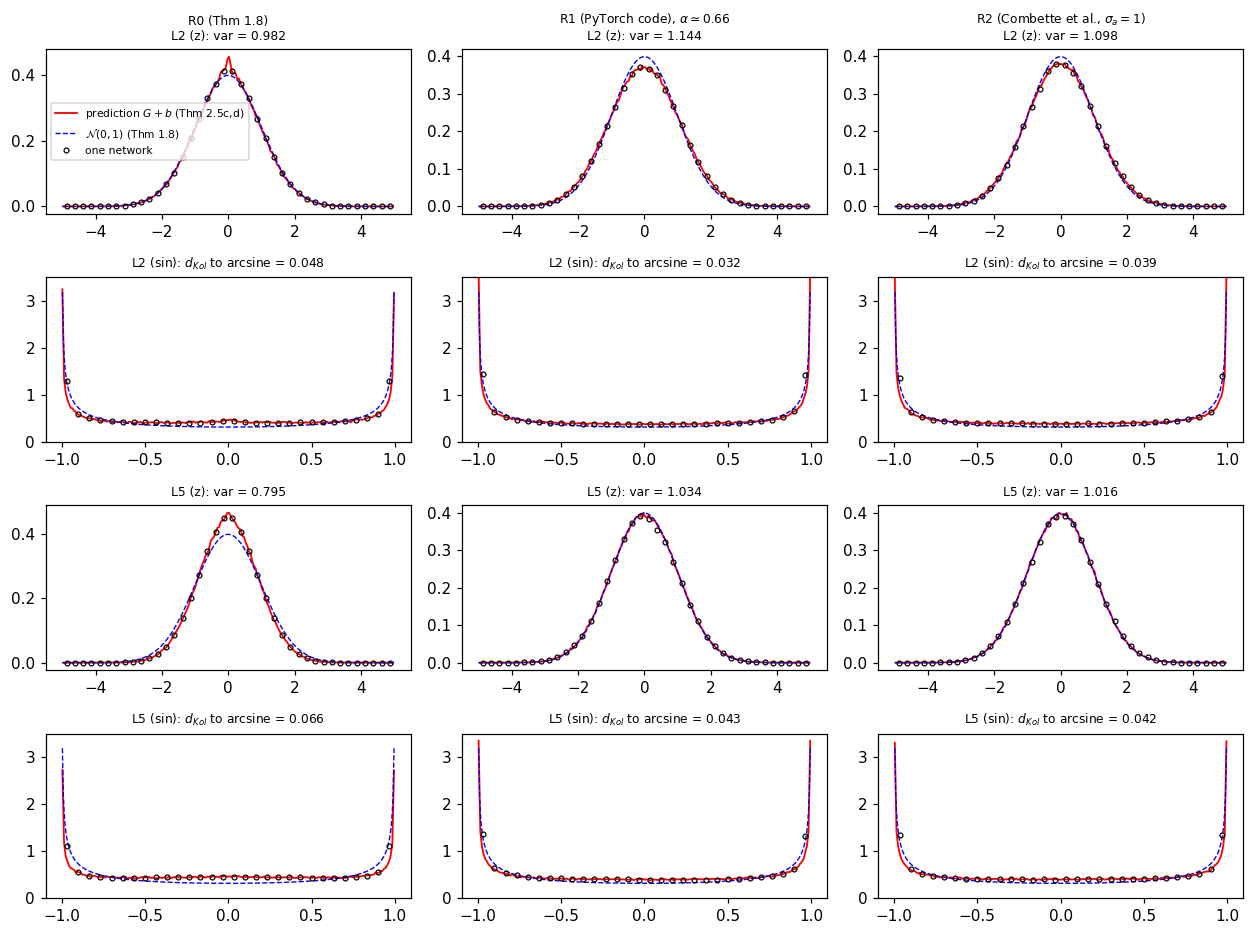

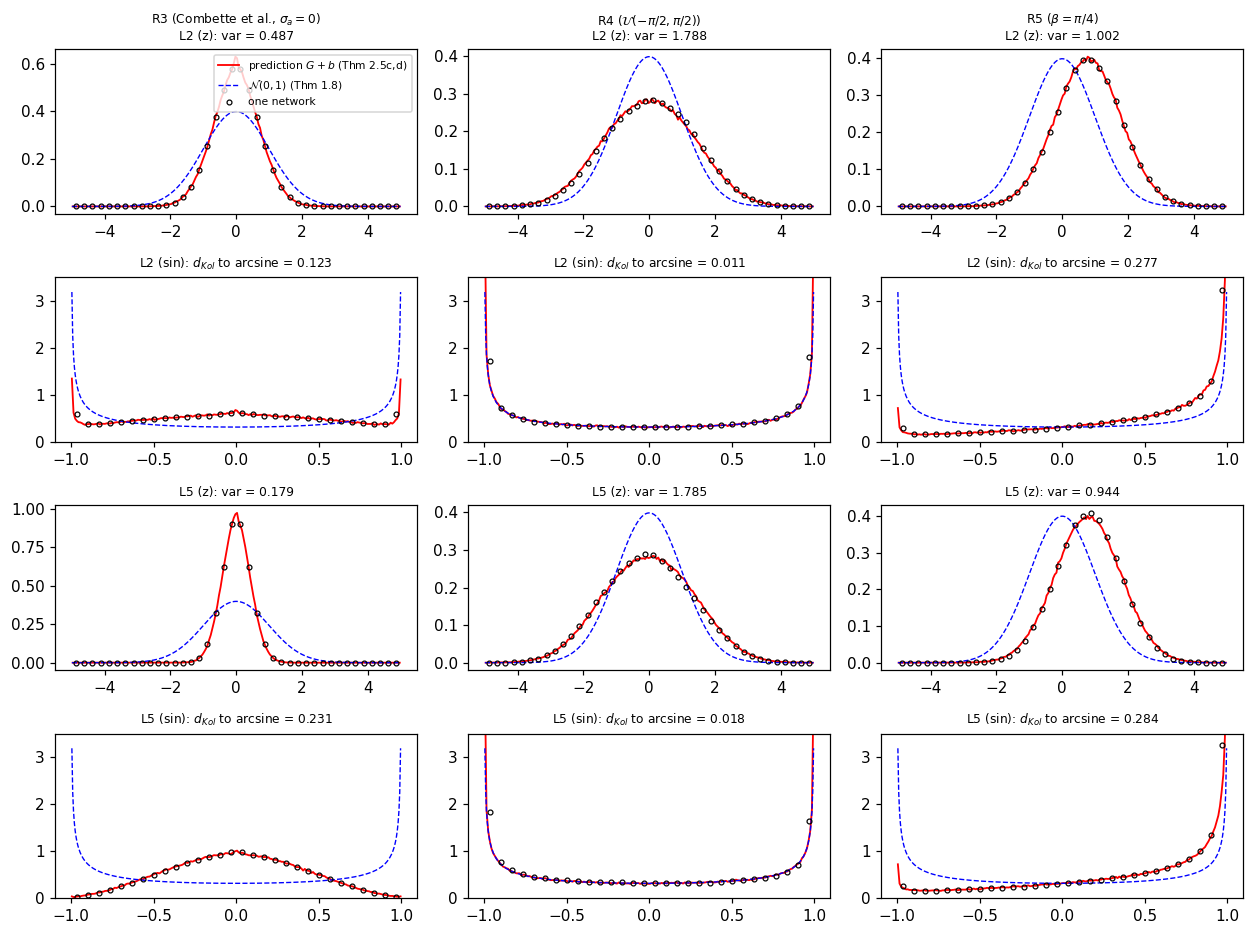

R0 L5: var measured 0.795, predicted 0.796; d_Kol(sin) 0.066
R1 L5: var measured 1.034, predicted 1.020; d_Kol(sin) 0.043
R2 L5: var measured 1.016, predicted 1.001; d_Kol(sin) 0.042
R5 L5: var measured 0.944, predicted 1.000; d_Kol(sin) 0.284
R4 L5: var measured 1.785, predicted 1.822; d_Kol(sin) 0.018
R3 L5: var measured 0.179, predicted 0.183; d_Kol(sin) 0.231


In [ ]:
x = np.linspace(-1, 1, 2048)
n = 2048
L = 5


def predicted_samples(s_l, bh, k=600000):
    idx = rng.integers(0, len(s_l), k)
    return rng.normal(0, np.sqrt(s_l[idx])) + bias_sample(bh, k)


zz = np.linspace(-5, 5, 400)
yy = np.linspace(-0.995, 0.995, 400)
SITZ = {}
for blk, suffix in [(0, "a"), (1, "b")]:
    fig, ax = plt.subplots(4, 3, figsize=(11.5, 8.6))
    for j, name in enumerate(CONFIGS[3 * blk : 3 * blk + 3]):
        CW, bf, bh = CONF[name](2048)
        Zs = simulate(x, n, L, W0, CW, bf, bh)
        s = s_theory(x, L, W0, CW, bf, bh)
        for r, l in enumerate([2, 5]):
            Z = Zs[l - 1].ravel()
            X = np.sin(Z)
            P = predicted_samples(s[l - 1], bh)
            a = ax[2 * r, j]
            hz, ez = np.histogram(P, bins=200, range=(-5, 5), density=True)
            a.plot(
                (ez[1:] + ez[:-1]) / 2,
                hz,
                "r",
                lw=1.2,
                label=ref(r"prediction $G+b$ (Thm §lois§c,d)"),
            )
            a.plot(zz, norm.pdf(zz), "b--", lw=0.9, label=r"$\mathcal{N}(0,1)$ (Thm 1.8)")
            c_, h_ = hist_points(Z, 40, (-5, 5))
            a.plot(c_, h_, color="k", label="one network", **MK)
            a.set_title(
                (LABEL[name] + (r", $\alpha\simeq0.66$" if name == "R1" else "") + "\n") * (r == 0)
                + f"L{l} (z): var = {np.var(Z):.3f}",
                fontsize=8,
            )
            a = ax[2 * r + 1, j]
            hx, ex = np.histogram(np.sin(P), bins=200, range=(-1, 1), density=True)
            a.plot((ex[1:] + ex[:-1]) / 2, hx, "r", lw=1.2)
            a.plot(yy, f_arc(yy), "b--", lw=0.9)
            c_, h_ = hist_points(X, 30, (-1, 1))
            a.plot(c_, h_, color="k", **MK)
            dk = ecdf_dist_arc(X[::7])
            a.set_ylim(0, 3.5)
            a.set_title(f"L{l} (sin): $d_{{Kol}}$ to arcsine = {dk:.3f}", fontsize=8)
            SITZ[(name, l)] = (np.var(Z), dk, np.mean(s[l - 1]) + bias_var(bh))
    ax[0, 0].legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(f"figs/fig_sitzmann_revisited_{suffix}.pdf")
    plt.show()
for name in CONF:
    for l in [5]:
        print(
            f"{name} L{l}: var measured {SITZ[(name,l)][0]:.3f}, predicted {SITZ[(name,l)][2]:.3f}; d_Kol(sin) {SITZ[(name,l)][1]:.3f}"
        )

## Figure — R1 (the PyTorch code) depends on $\alpha$

The effective hidden biases are $\mathcal U(-\alpha,\alpha)$ with $\alpha=\omega_0'/\sqrt n$, so $\gamma_b=\mathrm{sinc}(2\alpha)$. In the paper, R1 at width $n$ is the network of Definition 2.1 whose hidden-bias law $\mathcal U(-\alpha,\alpha)$ does not depend on the width (regime $\omega_0'=\alpha\sqrt n\to\infty$ for the hidden-bias frequency, with the first-layer frequency $\omega_0$ fixed); its infinite-width theory is drawn as a function of $n$ (bottom axis) or $\alpha$ (top axis). Lines: infinite-width theory for the corresponding bias law; markers: depth $L=12$, variance averaged over layers 6–12 and gradient ratios $g_{l-1}/g_l$ averaged over $l=6,\dots,11$, then over 8 independent networks for $n\leq256$, 4 for $n\leq512$, 2 for $n\leq1024$ and 1 above (`measure_deep`).

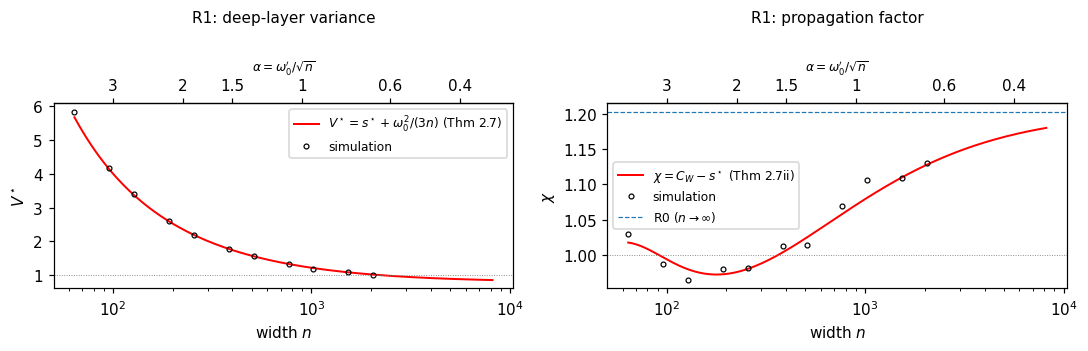

n=64: gamma=+0.125; V* theory 5.670, measured 5.838; chi theory 1.018, measured 1.030
n=96: gamma=-0.026; V* theory 4.128, measured 4.174; chi theory 0.997, measured 0.988
n=128: gamma=-0.157; V* theory 3.364, measured 3.390; chi theory 0.980, measured 0.964
n=192: gamma=-0.214; V* theory 2.590, measured 2.590; chi theory 0.973, measured 0.981
n=256: gamma=-0.152; V* theory 2.192, measured 2.200; chi theory 0.980, measured 0.981
n=384: gamma=+0.026; V* theory 1.778, measured 1.764; chi theory 1.004, measured 1.013
n=512: gamma=+0.177; V* theory 1.561, measured 1.568; chi theory 1.025, measured 1.015
n=768: gamma=+0.383; V* theory 1.332, measured 1.322; chi theory 1.058, measured 1.069
n=1024: gamma=+0.509; V* theory 1.212, measured 1.198; chi theory 1.081, measured 1.106


n=1536: gamma=+0.653; V* theory 1.085, measured 1.089; chi theory 1.110, measured 1.109
n=2048: gamma=+0.732; V* theory 1.019, measured 1.018; chi theory 1.128, measured 1.131


In [ ]:
NN = np.logspace(np.log10(64), np.log10(8192), 200)
Vth = [s_star(2.0, bias_gamma(R1_biases(n)[1])) + bias_var(R1_biases(n)[1]) for n in NN]
Cth = [chi_star(2.0, bias_gamma(R1_biases(n)[1])) for n in NN]
NE = [64, 96, 128, 192, 256, 384, 512, 768, 1024, 1536, 2048]
VE, CE = [], []
NNET = {64: 8, 96: 8, 128: 8, 192: 8, 256: 8, 384: 4, 512: 4, 768: 2, 1024: 2, 1536: 1, 2048: 1}
for n in NE:
    CW, bf, bh = CONF["R1"](n)
    V_, C_ = measure_deep(CW, bf, bh, n, nnet=NNET[n])
    VE.append(V_)
    CE.append(C_)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].semilogx(NN, Vth, "r", lw=1.3, label=ref(r"$V^\star=s^\star+\omega_0^2/(3n)$ (Thm §crit§)"))
ax[0].semilogx(NE, VE, color="k", label="simulation", **MK)
ax[0].axhline(1, color="gray", lw=0.6, ls=":")
ax[0].set_xlabel("width $n$")
ax[0].set_ylabel(r"$V^\star$")
ax[0].legend(fontsize=8)
ax[0].set_title("R1: deep-layer variance", fontsize=10, pad=24)
ax[1].semilogx(NN, Cth, "r", lw=1.3, label=ref(r"$\chi=C_W-s^\star$ (Thm §crit§ii)"))
ax[1].semilogx(NE, CE, color="k", label="simulation", **MK)
ax[1].axhline(1, color="gray", lw=0.6, ls=":")
ax[1].axhline(chi_star(2.0, 1.0), color="C0", lw=0.8, ls="--", label=r"R0 ($n\to\infty$)")
ax[1].set_xlabel("width $n$")
ax[1].set_ylabel(r"$\chi$")
ax[1].legend(fontsize=8)
ax[1].set_title("R1: propagation factor", fontsize=10, pad=24)
from matplotlib import ticker

for a in ax:
    top = a.secondary_xaxis(
        "top",
        functions=(
            lambda n: W0 / np.sqrt(np.maximum(n, 1e-9)),
            lambda al: (W0 / np.maximum(al, 1e-9)) ** 2,
        ),
    )
    top.set_xticks([0.4, 0.6, 1.0, 1.5, 2.0, 3.0])
    top.xaxis.set_major_formatter(ticker.FormatStrFormatter("%g"))
    top.xaxis.set_minor_locator(ticker.NullLocator())
    top.set_xlabel(r"$\alpha=\omega_0'/\sqrt{n}$", fontsize=8)
plt.tight_layout()
plt.savefig("figs/fig_R1_width.pdf")
plt.show()
R1W = dict(zip(NE, zip(VE, CE)))
for n in NE:
    g = bias_gamma(R1_biases(n)[1])
    print(
        f"n={n}: gamma={g:+.3f}; V* theory {s_star(2,g)+bias_var(R1_biases(n)[1]):.3f}, measured {R1W[n][0]:.3f}; chi theory {chi_star(2,g):.3f}, measured {R1W[n][1]:.3f}"
    )

## Figure — finite width: R5 is exact

At any width, $\mathrm{Var}\,Z^{(l+1)}=\mathrm{Var}(b)+\frac{C_W}{2}(1-\gamma_{Z^{(l)}})$ and $\gamma_{Z^{(l)}}=\gamma_{S^{(l)}}\gamma_b$, where $S^{(l)}=Z^{(l)}-b^{(l)}$ is the signal.
For R5 and R4, $\gamma_b=0$, hence $\gamma_{Z^{(l)}}=0$ exactly. For R4, the activations are moreover exactly arcsine at every width (Corollary 2.15). Width $n=4$, averages over 40 000 independent networks.

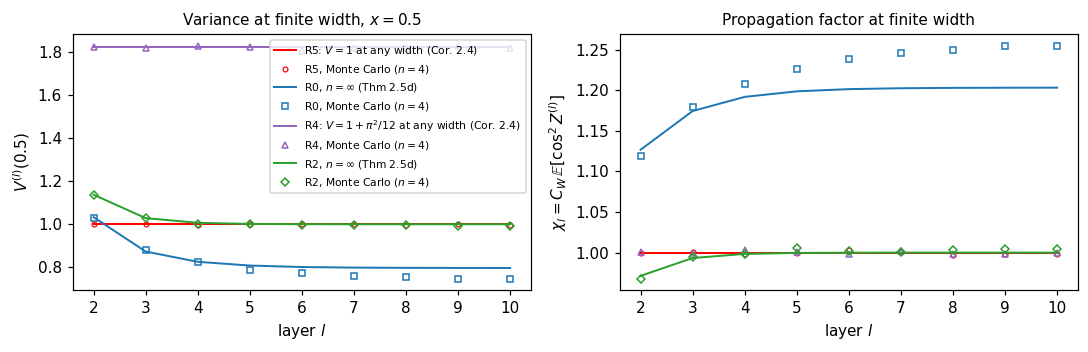

R4 variances [1.822 1.818 1.829 1.821 1.805 1.818 1.82  1.829 1.818] chi [1.    0.999 1.003 1.001 0.999 1.002 0.998 0.998 1.   ] d_Kol(sin Z, arcsine) [0.0013 0.0031 0.0021 0.003  0.003  0.0015 0.0034 0.0019 0.001 ]
R2 variances [1.138 1.03  1.003 0.999 0.996 0.999 0.996 0.993 0.994] theory n=inf [1.137 1.029 1.007 1.002 1.    1.    1.    1.    1.   ] chi [0.968 0.994 0.999 1.006 1.002 1.001 1.004 1.004 1.005]
R5 variances [0.999 0.999 0.998 1.001 1.003 1.003 0.998 0.999 0.999] chi [0.999 1.001 0.998 1.    1.003 1.001 0.997 0.999 0.999]
R0 variances [1.03  0.882 0.823 0.789 0.774 0.761 0.757 0.748 0.748] chi [1.119 1.179 1.208 1.226 1.238 1.246 1.25  1.255 1.254]


In [ ]:
rng_fw = np.random.default_rng(7)


def annealed(n, L, beta, nnet=40000, w0=W0, x=0.5, CW=2.0, half_width=0.0, gauss_var=0.0):
    # biases: beta + U(-half_width, half_width) + N(0, gauss_var), drawn independently for every network and neuron
    def bias():
        b = beta + (rng_fw.uniform(-half_width, half_width, (nnet, n)) if half_width > 0 else 0.0)
        return b + (rng_fw.normal(0, np.sqrt(gauss_var), (nnet, n)) if gauss_var > 0 else 0.0)

    W1 = rng_fw.uniform(-1, 1, (nnet, n))
    Z = w0 * W1 * x + bias()
    res = []
    acts = []
    for l in range(2, L + 1):
        W = rng_fw.uniform(-1, 1, (nnet, n, n)) * np.sqrt(3 * CW / n)
        Z = np.einsum("kij,kj->ki", W, np.sin(Z)) + bias()
        res.append((np.mean((Z - beta) ** 2), CW * np.mean(np.cos(Z) ** 2)))
        acts.append(np.sin(Z).ravel())
    return np.array(res), acts


L = 10
layers = np.arange(2, L + 1)
NFW = 4
r3, _ = annealed(NFW, L, np.pi / 4)
r0, _ = annealed(NFW, L, 0.0)
r4, acts4 = annealed(NFW, L, 0.0, half_width=np.pi / 2)
DK4 = np.array([ecdf_dist_arc(a) for a in acts4])
r2, _ = annealed(NFW, L, 0.0, CW=CW_R2, gauss_var=CB_R2)
s2inf = s_theory(np.array([0.5]), L, W0, CW_R2, ("gauss", 0.0, CB_R2), ("gauss", 0.0, CB_R2))
V2inf = [v[0] + CB_R2 for v in s2inf[1:]]
chi2_inf = [CW_R2 / 2 * (1 + np.exp(-2 * CB_R2) * np.exp(-2 * v[0])) for v in s2inf[1:]]
V4 = 1 + np.pi**2 / 12
sinf = s_theory(np.array([0.5]), L, W0, 2.0, ("none",), ("none",))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(
    layers, np.ones_like(layers), "r", lw=1.3, label=ref(r"R5: $V=1$ at any width (Cor. §R5§)")
)
ax[0].plot(layers, r3[:, 0], color="r", label=f"R5, Monte Carlo ($n={NFW}$)", **MK)
ax[0].plot(
    layers, [v[0] for v in sinf[1:]], "C0", lw=1.3, label=ref(r"R0, $n=\infty$ (Thm §lois§d)")
)
ax[0].plot(
    layers,
    r0[:, 0],
    color="C0",
    marker="s",
    ls="none",
    ms=3.5,
    mfc="none",
    label=f"R0, Monte Carlo ($n={NFW}$)",
)
ax[0].plot(
    layers,
    V4 * np.ones_like(layers),
    "C4",
    lw=1.3,
    label=ref(r"R4: $V=1+\pi^2/12$ at any width (Cor. §R5§)"),
)
ax[0].plot(
    layers,
    r4[:, 0],
    color="C4",
    marker="^",
    ls="none",
    ms=3.5,
    mfc="none",
    label=f"R4, Monte Carlo ($n={NFW}$)",
)
ax[0].plot(layers, V2inf, "C2", lw=1.3, label=ref(r"R2, $n=\infty$ (Thm §lois§d)"))
ax[0].plot(
    layers,
    r2[:, 0],
    color="C2",
    marker="D",
    ls="none",
    ms=3.5,
    mfc="none",
    label=f"R2, Monte Carlo ($n={NFW}$)",
)
ax[0].set_xlabel("layer $l$")
ax[0].set_ylabel(r"$V^{(l)}(0.5)$")
ax[0].legend(fontsize=7)
ax[0].set_title("Variance at finite width, $x=0.5$", fontsize=10)
chi_inf = [2 / 2 * (1 + np.exp(-2 * v[0])) for v in sinf[1:]]
ax[1].plot(layers, np.ones_like(layers), "r", lw=1.3)
ax[1].plot(layers, r3[:, 1], color="r", **MK)
ax[1].plot(layers, chi_inf, "C0", lw=1.3)
ax[1].plot(layers, r0[:, 1], color="C0", marker="s", ls="none", ms=3.5, mfc="none")
ax[1].plot(layers, r4[:, 1], color="C4", marker="^", ls="none", ms=3.5, mfc="none")
ax[1].plot(layers, chi2_inf, "C2", lw=1.3)
ax[1].plot(layers, r2[:, 1], color="C2", marker="D", ls="none", ms=3.5, mfc="none")
ax[1].set_xlabel("layer $l$")
ax[1].set_ylabel(r"$\chi_l=C_W\,\mathbb{E}[\cos^2 Z^{(l)}]$")
ax[1].set_title("Propagation factor at finite width", fontsize=10)
plt.tight_layout()
plt.savefig("figs/fig_finite_width.pdf")
plt.show()
FW = (r3, r0, r4, DK4)
print(
    "R4 variances",
    np.round(r4[:, 0], 3),
    "chi",
    np.round(r4[:, 1], 3),
    "d_Kol(sin Z, arcsine)",
    np.round(DK4, 4),
)
print(
    "R2 variances",
    np.round(r2[:, 0], 3),
    "theory n=inf",
    np.round(V2inf, 3),
    "chi",
    np.round(r2[:, 1], 3),
)
print("R5 variances", np.round(r3[:, 0], 3), "chi", np.round(r3[:, 1], 3))
print("R0 variances", np.round(r0[:, 0], 3), "chi", np.round(r0[:, 1], 3))

## Figure — propagation factor

Left: without bias, $\chi=s^\star\coth s^\star$, with one network per $C_W$ measured as in the R1 figure. Right: measured ratios $g_{l-1}/g_l$ of back-propagated gradient variances (width 2048, and 512 for R1; one network, linear read-out with Gaussian weights) against the layer-wise prediction $\chi_l=\frac{C_W}{2}(1+\gamma_b e^{-2s^{(l)}})$ averaged over the inputs, which equals $\chi=C_W-s^\star$ at the fixed point.

R0 (n=2048): predicted chi_l = [1.204 1.205 1.206 1.207 1.207 1.207 1.204 1.192], measured ratios = [1.188 1.185 1.212 1.218 1.188 1.201 1.21  1.238]
R1 (n=512): predicted chi_l = [1.025 1.025 1.025 1.025 1.025 1.025 1.025 1.025], measured ratios = [1.022 1.043 1.057 0.994 1.052 1.012 1.037 1.031]


R2 (n=2048): predicted chi_l = [1.    1.    1.    1.    1.    1.    0.999 0.995], measured ratios = [0.956 0.958 1.015 0.984 0.997 0.976 1.    1.008]


R3 (n=2048): predicted chi_l = [0.915 0.907 0.897 0.885 0.869 0.847 0.817 0.771], measured ratios = [0.868 0.881 0.861 0.868 0.86  0.813 0.835 0.754]


R4 (n=2048): predicted chi_l = [1. 1. 1. 1. 1. 1. 1. 1.], measured ratios = [0.974 0.971 1.023 0.986 0.985 1.029 1.014 1.004]


R5 (n=2048): predicted chi_l = [1. 1. 1. 1. 1. 1. 1. 1.], measured ratios = [1.032 0.968 0.959 1.015 0.994 1.004 1.008 0.989]
no bias C_W=1.400: measured (V, chi) = (0.370, 1.052); theory s* = 0.358, chi = 1.042
no bias C_W=1.600: measured (V, chi) = (0.516, 1.084); theory s* = 0.514, chi = 1.086
no bias C_W=1.800: measured (V, chi) = (0.664, 1.156); theory s* = 0.659, chi = 1.141
no bias C_W=2.000: measured (V, chi) = (0.793, 1.212); theory s* = 0.797, chi = 1.203
no bias C_W=2.200: measured (V, chi) = (0.919, 1.258); theory s* = 0.928, chi = 1.272
no bias C_W=2.313: measured (V, chi) = (1.005, 1.321); theory s* = 1.000, chi = 1.313
no bias C_W=2.500: measured (V, chi) = (1.112, 1.386); theory s* = 1.116, chi = 1.384
no bias C_W=2.800: measured (V, chi) = (1.283, 1.512); theory s* = 1.295, chi = 1.505
no bias C_W=3.100: measured (V, chi) = (1.460, 1.632); theory s* = 1.468, chi = 1.632
no bias C_W=3.400: measured (V, chi) = (1.636, 1.766); theory s* = 1.635, chi = 1.765
no bias C_W=3.

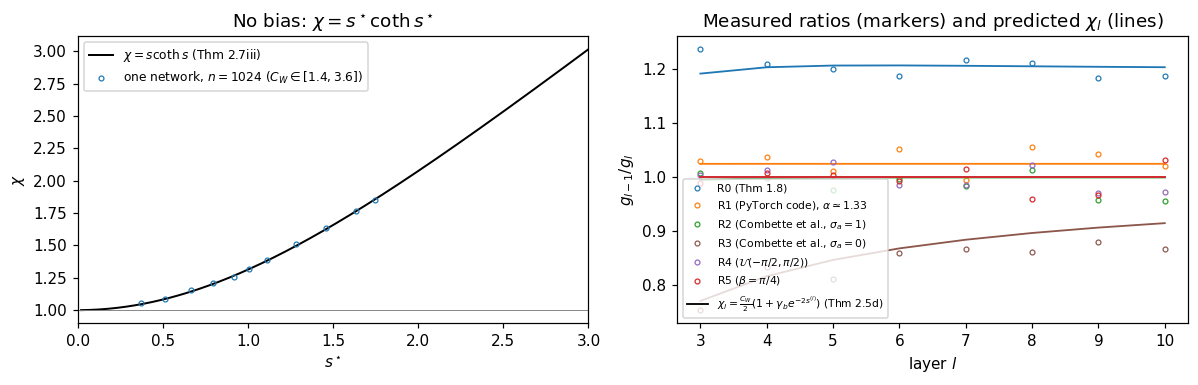

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
Vv = np.linspace(0.02, 3, 400)
ax[0].plot(Vv, Vv / np.tanh(Vv), "k", lw=1.3, label=ref(r"$\chi=s\coth s$ (Thm §crit§iii)"))
ax[0].axhline(1, color="gray", lw=0.6)
CHI0 = {}
for cw in [1.4, 1.6, 1.8, 2.0, 2.2, 2 / (1 - np.exp(-2)), 2.5, 2.8, 3.1, 3.4, 3.6]:
    V_, C_ = measure_deep(cw, ("none",), ("none",), 1024)
    CHI0[cw] = (V_, C_, s_star(cw, 1.0))
    ax[0].plot(V_, C_, color="C0", **MK)
ax[0].plot([], [], color="C0", label=r"one network, $n=1024$ ($C_W\in[1.4,3.6]$)", **MK)
ax[0].set_xlim(0, 3)
ax[0].set_xlabel(r"$s^\star$")
ax[0].set_ylabel(r"$\chi$")
ax[0].legend(fontsize=8)
ax[0].set_title(r"No bias: $\chi=s^\star\coth s^\star$")
M, L = 400, 10
xg = np.linspace(-1, 1, M)
CHIM = {}
for k, name in enumerate(CONFIGS):
    n = 512 if name == "R1" else 2048
    CW, bf, bh = CONF[name](n)
    Zs, Ws = simulate(xg, n, L, W0, CW, bf, bh, keep_W=True)
    ratios = grad_ratios(Zs, Ws, M, n)
    # layer-wise prediction chi_l = (C_W/2)(1 + gamma_b exp(-2 s^(l)(x))), averaged over the inputs
    s_l = s_theory(xg, L, W0, CW, bf, bh)
    pred = [
        np.mean(CW / 2 * (1 + bias_gamma(bh) * np.exp(-2 * s_l[l - 1]))) for l in range(L, 2, -1)
    ]
    CHIM[name] = (np.array(pred), np.array(ratios))
    lab = LABEL[name] + (r", $\alpha\simeq1.33$" if name == "R1" else "")
    ax[1].plot(range(L, 2, -1), ratios, color=COL[name], label=lab, **MK)
    ax[1].plot(range(L, 2, -1), pred, color=COL[name], lw=1.2)
    print(
        f"{name} (n={n}): predicted chi_l = {np.round(pred, 3)}, measured ratios = {np.round(ratios, 3)}"
    )
ax[1].plot(
    [],
    [],
    "k",
    lw=1.2,
    label=ref(r"$\chi_l=\frac{C_W}{2}(1+\gamma_b e^{-2s^{(l)}})$ (Thm §lois§d)"),
)
ax[1].set_xlabel("layer $l$")
ax[1].set_ylabel(r"$g_{l-1}/g_l$")
ax[1].legend(fontsize=7)
ax[1].set_title(r"Measured ratios (markers) and predicted $\chi_l$ (lines)")
for cw, v in CHI0.items():
    print(
        f"no bias C_W={cw:.3f}: measured (V, chi) = ({v[0]:.3f}, {v[1]:.3f}); theory s* = {v[2]:.3f}, chi = {v[2]/np.tanh(v[2]):.3f}"
    )
plt.tight_layout()
plt.savefig("figs/fig_chi.pdf")
plt.show()

## Figure — distance to the arcsine law: Gaussian phase and uniform phase

(a) Kolmogorov distance of $\sin\mathcal N(\beta,s)$ to the arcsine law: exact value from the Kolmogorov identity (lines), asymptotic equivalents $e^{-2s}/\pi$ ($\beta\in\pi\mathbb Z$) and $\frac2\pi|\sin\beta|e^{-s/2}$ (dashed), Monte Carlo with $2\cdot10^6$ samples (markers, shown above the sampling noise).
(b) Uniform phase $Y=\sin(aU+\beta)$, $U\sim\mathcal U(-1,1)$: $a\times d_{\mathrm{Kol}}$ from the closed forms (lines) and Monte Carlo with $10^6$ samples (markers).

**Numerical method.** (a) Kolmogorov identity truncated at 80 terms, supremum over a uniform subdivision of $]0,\pi[$ into 20 000 intervals. (b) Closed form of Corollary 2.13 through $\Lambda_0(\theta)=\sum_{m\ge1}\cos(m\theta)/m^2=\frac{\pi^2}{6}-\frac{\pi\theta}{2}+\frac{\theta^2}{4}$ (Theorem B.9), supremum over a uniform subdivision of $]0,\pi[$ into 6 000 intervals.

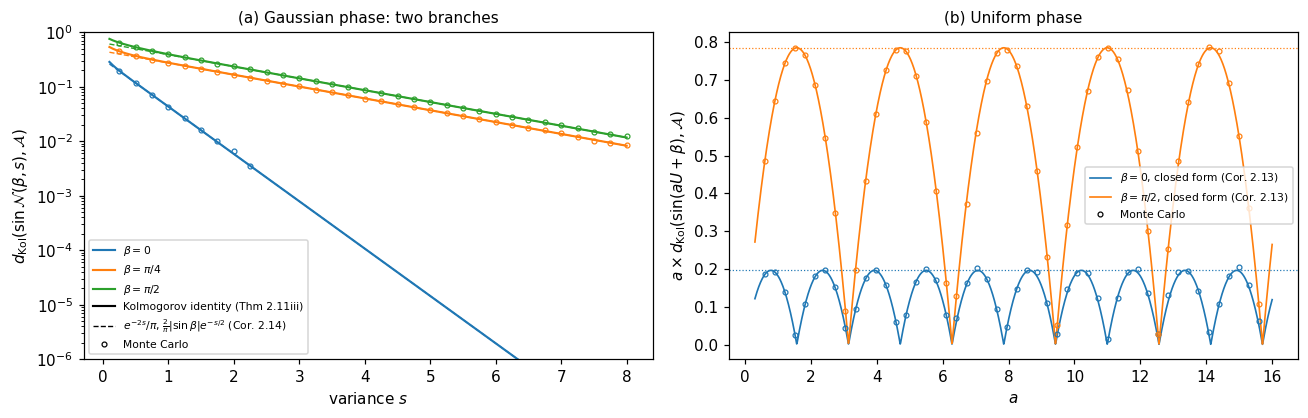

max |Monte Carlo - closed form| for a d_Kol: 0.01702694265609493


a=pi/2, beta=0: 3.149695106935921e-16 ; a=2.2: 0.0857051670017255 ; max a*dKol (beta=0) = 0.19634571787383612
R1 n=256: d_Kol of limit activations = 0.0063
R1 n=2048: d_Kol of limit activations = 0.0407


In [ ]:
def Lambda0(t):
    t = np.mod(t, 2 * np.pi)
    return np.pi**2 / 6 - np.pi * t / 2 + t**2 / 4


VV = (
    np.arange(1, 6000) * np.pi / 6000
)  # interior nodes of a uniform subdivision of (0, pi) into 6 000 intervals


def dkol_unif(a, beta):
    bp = beta - np.pi / 2
    return np.max(
        np.abs(-sum(Lambda0(a - w) - Lambda0(a + w) for w in (VV + bp, VV - bp)) / (2 * np.pi * a))
    )


fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
DKMC = {}
ss = np.linspace(0.1, 8, 160)
for beta, col, lab in [
    (0.0, "C0", r"$\beta=0$"),
    (np.pi / 4, "C1", r"$\beta=\pi/4$"),
    (np.pi / 2, "C2", r"$\beta=\pi/2$"),
]:
    ax[0].semilogy(ss, [dkol_gauss(s, beta) for s in ss], color=col, lw=1.4, label=lab)
    eq = np.exp(-2 * ss) / np.pi if beta == 0 else 2 / np.pi * abs(np.sin(beta)) * np.exp(-ss / 2)
    ax[0].semilogy(ss, eq, "--", color=col, lw=0.9)
    for s in np.arange(0.25, 8.01, 0.25):
        d = ecdf_dist_arc(np.sin(rng.normal(0, np.sqrt(s), 2_000_000) + beta))
        if d > 3e-3:
            DKMC[(beta, s)] = d
            ax[0].semilogy(s, d, color=col, **MK)
ax[0].semilogy([], [], "k", lw=1.4, label=ref("Kolmogorov identity (Thm §cheb§iii)"))
ax[0].semilogy(
    [],
    [],
    "k--",
    lw=0.9,
    label=ref(r"$e^{-2s}/\pi$, $\frac{2}{\pi}|\sin\beta|e^{-s/2}$ (Cor. §gauss§)"),
)
ax[0].semilogy([], [], color="k", label="Monte Carlo", **MK)
ax[0].set_xlabel("variance $s$")
ax[0].set_ylabel(r"$d_{\mathrm{Kol}}(\sin\mathcal{N}(\beta,s),\mathcal{A})$")
ax[0].set_ylim(1e-6, 1)
ax[0].legend(fontsize=7)
ax[0].set_title("(a) Gaussian phase: two branches", fontsize=10)
A = np.linspace(0.3, 16, 1500)
ax[1].plot(
    A,
    [a * dkol_unif(a, 0.0) for a in A],
    "C0",
    lw=1.1,
    label=ref(r"$\beta=0$, closed form (Cor. §unif§)"),
)
ax[1].plot(
    A,
    [a * dkol_unif(a, np.pi / 2) for a in A],
    "C1",
    lw=1.1,
    label=ref(r"$\beta=\pi/2$, closed form (Cor. §unif§)"),
)
ax[1].axhline(np.pi / 16, color="C0", ls=":", lw=0.8)
ax[1].axhline(np.pi / 4, color="C1", ls=":", lw=0.8)
UMC = []
for a_mc in np.linspace(0.6, 15.6, 50):
    for beta, col in [(0.0, "C0"), (np.pi / 2, "C1")]:
        v = a_mc * ecdf_dist_arc(np.sin(a_mc * rng.uniform(-1, 1, 1_000_000) + beta))
        ax[1].plot(a_mc, v, color=col, **MK)
        UMC.append(abs(v - a_mc * dkol_unif(a_mc, beta)))
ax[1].plot([], [], color="k", label="Monte Carlo", **MK)
ax[1].set_xlabel("$a$")
ax[1].set_ylabel(r"$a\times d_{\mathrm{Kol}}(\sin(aU+\beta),\mathcal{A})$")
ax[1].legend(fontsize=7)
ax[1].set_title("(b) Uniform phase", fontsize=10)
plt.tight_layout()
plt.savefig("figs/fig_arcsine.pdf")
plt.show()
print("max |Monte Carlo - closed form| for a d_Kol:", max(UMC))
print(
    "a=pi/2, beta=0:",
    dkol_unif(np.pi / 2, 0.0),
    "; a=2.2:",
    dkol_unif(2.2, 0.0),
    "; max a*dKol (beta=0) =",
    max(a * dkol_unif(a, 0.0) for a in A),
)
for nn in [256, 2048]:
    Aw = W0 / np.sqrt(nn)
    g = sinc(2 * Aw)
    s = s_star(2.0, g)
    print(
        f"R1 n={nn}: d_Kol of limit activations = {dkol_from_moments(moments_phase(s, 0.0, lambda k: sinc(k*Aw))):.4f}"
    )

## Figure (appendix) — discrepancy obstruction

Gaussian phase, $\beta=0$: discrepancy of the wrapped law and its lower bound, Erdős–Turán bound with optimal constants, Chebyshev bound, exact Kolmogorov distance of the sine.

**Numerical method.** Density of the wrapped normal law truncated at 60 harmonics (tail $\le e^{-s\cdot60^2/2}$), on 200 000 points of $[-\pi,\pi]$. For this unimodal density, the discrepancy (supremum over arcs) equals $\int(p-\frac1{2\pi})_+\,d\theta$, computed by a Riemann sum.

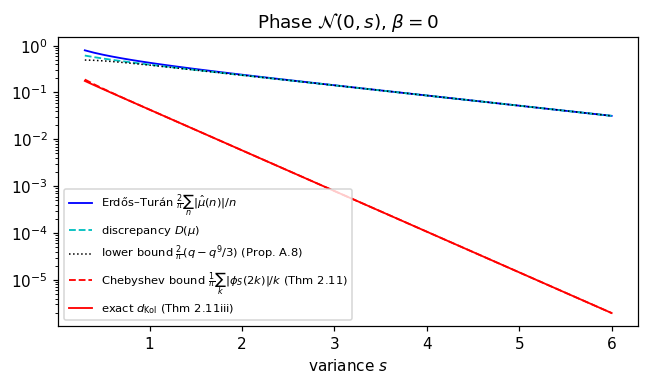

In [ ]:
th = np.linspace(-np.pi, np.pi, 200000)
dth = th[1] - th[0]


def discrepancy_wrapped_normal(s):
    p = (1 + 2 * sum(np.exp(-s * n * n / 2) * np.cos(n * th) for n in range(1, 60))) / (2 * np.pi)
    return np.sum(np.clip(p - 1 / (2 * np.pi), 0, None)) * dth


ss = np.linspace(0.3, 6, 58)
D = np.array([discrepancy_wrapped_normal(s) for s in ss])
qq = np.exp(-ss / 2)
ET = np.array([2 / np.pi * sum(np.exp(-s * n * n / 2) / n for n in range(1, 80)) for s in ss])
OURS = np.array([1 / np.pi * sum(np.exp(-2 * s * k * k) / k for k in range(1, 80)) for s in ss])
EX = np.array([dkol_gauss(s, 0.0) for s in ss])
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogy(ss, ET, "b", lw=1.2, label=r"Erdős–Turán $\frac{2}{\pi}\sum_n|\hat\mu(n)|/n$")
ax.semilogy(ss, D, "c--", lw=1.2, label=r"discrepancy $D(\mu)$")
ax.semilogy(
    ss,
    2 / np.pi * (qq - qq**9 / 3),
    "k:",
    lw=1,
    label=ref(r"lower bound $\frac{2}{\pi}(q-q^9/3)$ (Prop. §obst§)"),
)
ax.semilogy(
    ss,
    OURS,
    "r--",
    lw=1.2,
    label=ref(r"Chebyshev bound $\frac{1}{\pi}\sum_k|\phi_S(2k)|/k$ (Thm §cheb§)"),
)
ax.semilogy(ss, EX, "r", lw=1.2, label=ref(r"exact $d_{\mathrm{Kol}}$ (Thm §cheb§iii)"))
ax.set_xlabel("variance $s$")
ax.legend(fontsize=7.5)
ax.set_title(r"Phase $\mathcal{N}(0,s)$, $\beta=0$")
plt.tight_layout()
plt.savefig("figs/fig_obstruction.pdf")
plt.show()

## Table — the six configurations

Fixed-point quantities in infinite width, and Kolmogorov distances of the limit activations to the arcsine law and of the limit pre-activations to $\mathcal N(0,1)$ ($\mathcal N(\pi/4,1)$ for R5).

**Numerical method.** Fixed point by iteration (see above); distance of the activations to the arcsine law by the Kolmogorov identity with the exact bias coefficients. Distance of the limit pre-activation $G+b$, $G\sim\mathcal N(0,s^\star)$, to $\mathcal N(\beta,1)$: for uniform biases the distribution function of $G+b$ is the average of $\Phi((t-u)/\sqrt{s^\star})$ over 8 000 points $u\in[-\alpha,\alpha]$, and the supremum is taken over 4 000 points $t\in[-10,10]$; for Gaussian or constant biases $G+b$ is Gaussian and the distance is computed directly.

In [ ]:
rows = [
    ("R0", "R0"),
    ("R1 alpha=1.875", ("R1", 256)),
    ("R1 alpha=0.663", ("R1", 2048)),
    ("R2", "R2"),
    ("R3", "R3"),
    ("R4", "R4"),
    ("R5", "R5"),
]
tt = np.linspace(-10, 10, 4000)


def dkol_preact_limit(s, bh):
    # Kolmogorov distance between the limit law of G + b, G ~ N(0, s), and N(beta, 1)
    beta_ = bias_mean(bh)
    if bh[0] == "unif":
        u = np.linspace(bh[1] - bh[2], bh[1] + bh[2], 8000)
        F = np.mean(norm.cdf((tt[:, None] - u[None, :]) / np.sqrt(s)), axis=1)
    else:
        F = norm.cdf((tt - beta_) / np.sqrt(s + bias_var(bh)))
    return np.max(np.abs(F - norm.cdf(tt - beta_)))


TABLE = {}
for label, key in rows:
    CW, bf, bh = CONF[key[0]](key[1]) if isinstance(key, tuple) else CONF[key]()
    g = bias_gamma(bh)
    s = s_star(CW, g)
    V = s + bias_var(bh)
    if s < 1e-3:
        # degenerate fixed point (R3): the limit law is the point mass at 0, at distance 1/2 from both laws
        d_arc, d_gau = 0.5, 0.5
    else:
        d_arc = dkol_from_moments(moments_phase(s, bias_mean(bh), lambda k: bias_phi(bh, k)))
        d_gau = dkol_preact_limit(s, bh)
    TABLE[label] = (CW, bias_gamma(bf), g, s, V, CW - s, d_arc, d_gau)
    print(
        f"{label:12s} C_W={CW:6.3f} gamma1={bias_gamma(bf):+7.3f} gamma={g:+7.3f} s*={s:7.4f} V*={V:7.4f} chi={CW-s:7.4f} dKol(sinZ,arcsine)={d_arc:7.4f} dKol(Z,N(beta,1))={d_gau:7.4f}"
    )

R0           C_W= 2.000 gamma1= +1.000 gamma= +1.000 s*= 0.7968 V*= 0.7968 chi= 1.2032 dKol(sinZ,arcsine)= 0.0647 dKol(Z,N(beta,1))= 0.0275


R1 alpha=1.875 C_W= 2.000 gamma1= -0.005 gamma= -0.152 s*= 1.0198 V*= 2.1917 chi= 0.9802 dKol(sinZ,arcsine)= 0.0063 dKol(Z,N(beta,1))= 0.1055


R1 alpha=0.663 C_W= 2.000 gamma1= -0.005 gamma= +0.732 s*= 0.8721 V*= 1.0186 chi= 1.1279 dKol(sinZ,arcsine)= 0.0407 dKol(Z,N(beta,1))= 0.0028
R2           C_W= 1.762 gamma1= +0.621 gamma= +0.621 s*= 0.7616 V*= 1.0000 chi= 1.0000 dKol(sinZ,arcsine)= 0.0431 dKol(Z,N(beta,1))= 0.0000
R3           C_W= 1.000 gamma1= +1.000 gamma= +1.000 s*= 0.0000 V*= 0.0000 chi= 1.0000 dKol(sinZ,arcsine)= 0.5000 dKol(Z,N(beta,1))= 0.5000


R4           C_W= 2.000 gamma1= +0.000 gamma= +0.000 s*= 1.0000 V*= 1.8225 chi= 1.0000 dKol(sinZ,arcsine)= 0.0000 dKol(Z,N(beta,1))= 0.0797
R5           C_W= 2.000 gamma1= +0.000 gamma= +0.000 s*= 1.0000 V*= 1.0000 chi= 1.0000 dKol(sinZ,arcsine)= 0.2747 dKol(Z,N(beta,1))= 0.0000
